In [101]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

In [102]:
words = open('names.txt', 'r').read().splitlines()
chars = sorted(list(set(''.join(words))))
s_to_i = {s: i+1 for i, s in enumerate(chars)}
s_to_i['.'] = 0
i_to_s = {i:s for s, i in s_to_i.items()}

### Wavenet architecture

We introduce the concept of convolutions, since our current MLP setup squishes all of our information into a single layer quite quickly.

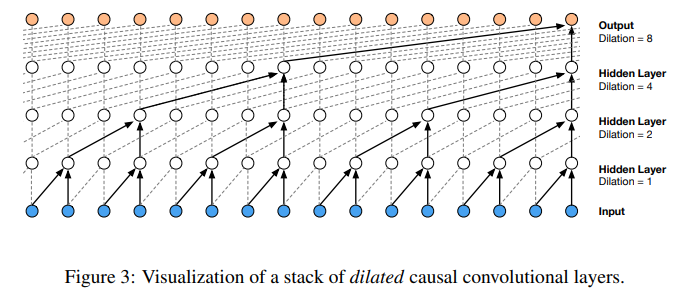

We instead implement this wavenet, which slowly goes from 1 char to bigram to 4gram to 8gram over several layers

In [103]:
# Matrix multiplication interlude
# to implement the above architecture, lets go deeper into the linear layers

# recall what is actually happening
test1 = torch.ones((4, 200)) @ torch.ones((200, 27)) + torch.ones(27)
print(test1.shape) # this is a 4x27 matrix after the matmul, and then the addition term gets broadcast  4 times down the rows

# the torch @ symbol is quite powerful - it only does it based on the final dimension while preserving all of the original structure
test2 = torch.ones(4, 5, 20) @ torch.ones(20, 27)
print(test2.shape) # 4, 5, 27

# now for this wavenet, we want to group certain observations together to pass in to the next layer
# so instead of passing in [1, 2, 3, 4, 5, 6, 7, 8] (as we were doing when we flatten our embedding matrix), we want to pass [(1, 2), (3, 4), (5, 6), (7, 8)], i.e. processing the pairs in parallel
# but in our case imagine each integer is a 10dim embedding

# can simply use the view function again 
e = torch.randn(4, 8, 10) # 4 x observations, 8 block size, 10 dimension embedding
# we want to group each of the blocks into bigrams, so this would be (4, 4, 2, 10), and then do the flattening to pass into our network ending with (4, 4, 20)
# use simple view function
flat = FlattenConsecutive(2)
flat(e).shape
# implement this bigram grouping into the flatten module


torch.Size([4, 27])
torch.Size([4, 5, 27])


torch.Size([4, 4, 20])

In [104]:
block_size = 8 # start with block size 8

# create the dataset, now we have 228146 datapoints
# implement test and training splits
def build_dataset(words):
    X, Y = [], []

    for w in words:
        context = [0] * block_size
        for ch in w+'.':
            ix = s_to_i[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

# create the datasets
X_train, Y_train = build_dataset(words[:n1])
X_val, Y_val = build_dataset(words[n1:n2])
X_test, Y_test = build_dataset(words[n2:])

In [105]:
# Near copy paste of the layers we have developed in Part 3

# -----------------------------------------------------------------------------------------------
from typing import Any


class Linear:
  
  def __init__(self, fan_in, fan_out, bias=True):
    self.weight = torch.randn((fan_in, fan_out)) / fan_in**0.5 # note: kaiming init
    self.bias = torch.zeros(fan_out) if bias else None
  
  def __call__(self, x):
    self.out = x @ self.weight
    if self.bias is not None:
      self.out += self.bias
    return self.out
  
  def parameters(self):
    return [self.weight] + ([] if self.bias is None else [self.bias])

# -----------------------------------------------------------------------------------------------
class BatchNorm1d:
  
  def __init__(self, dim, eps=1e-5, momentum=0.1):
    self.eps = eps
    self.momentum = momentum
    self.training = True
    # parameters (trained with backprop)
    self.gamma = torch.ones(dim)
    self.beta = torch.zeros(dim)
    # buffers (trained with a running 'momentum update')
    self.running_mean = torch.zeros(dim)
    self.running_var = torch.ones(dim)
  
  def __call__(self, x):
    # calculate the forward pass
    if self.training:
      # throw in this part for the wavenet - we want to take the mean over the entire batch and all of its examples, regardless of the way its grouped
      # broadcasting rules means this would fail quietly for a 3 dimensional tensor
      # now we aggregate over the first 2 dimensions to give the mean and variance for the entire training batch, and then we can broadcast it back onto the training set
      if x.ndim == 2:
        dim = 0
      elif x.ndim == 3:
        dim = (0,1)
      xmean = x.mean(dim, keepdim=True) # batch mean
      xvar = x.var(dim, keepdim=True) # batch variance
    else:
      xmean = self.running_mean
      xvar = self.running_var
    xhat = (x - xmean) / torch.sqrt(xvar + self.eps) # normalize to unit variance
    self.out = self.gamma * xhat + self.beta
    # update the buffers
    if self.training:
      with torch.no_grad():
        self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
        self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar
    return self.out
  
  def parameters(self):
    return [self.gamma, self.beta]

# -----------------------------------------------------------------------------------------------
class Tanh:
  def __call__(self, x):
    self.out = torch.tanh(x)
    return self.out
  def parameters(self):
    return []

# now we want to create modules for other operations in our forward pass
# -----------------------------------------------------------------------------------------------
# the embedding matrix lookup and concatenation emb -> embcat (split into two modules cos thats how pytorch does it)
class Embedding:
  
  def __init__(self, num_embeddings, embedding_dim):
    self.weight = torch.randn((num_embeddings, embedding_dim))
    
  def __call__(self, IX):
    self.out = self.weight[IX]
    return self.out
  
  def parameters(self):
    return [self.weight]

class FlattenConsecutive:
  def __init__(self, n) -> None:
    self.n = n

  def __call__(self, x):
    B, T, C = x.shape
    x = x.view(B, T//self.n, C*self.n)
    if x.shape[1] == 1: # get rid of a 1 dimension
      x = x.squeeze(1)
    self.out = x
    return self.out

  def parameters(self):
    return []
  
# create a class that stores all of the layers and can call them in the correct order
class Sequential:
  def __init__(self, layers) -> None:
    self.layers = layers

  def __call__(self, x) -> Any:
    for layer in self.layers:
      x = layer(x)
    self.out = x
    return self.out

  def parameters(self):
    return [p for layer in self.layers for p in layer.parameters()]

In [106]:
torch.manual_seed(42)

In [107]:
n_embd = 24
n_hidden = 128
vocab_size = 27

# start with simple net linear -> bnorm -> tanhactivation -> linear logits
# now add the embed and flattening as layers, no longer need to create C
model = Sequential([
    Embedding(vocab_size, n_embd), 
    FlattenConsecutive(2), # note if the input here matches the block size, behaviour should be unchanged, for the wavenet we want to use 2
    Linear((2 *  n_embd), n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(), # note we convert the input layer to embedding dimension * 2, since we are only passing in pairs of inputs
    FlattenConsecutive(2), Linear((2 *  n_hidden), n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(), # repeat the same thing
    FlattenConsecutive(2), Linear((2 *  n_hidden), n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
    Linear(n_hidden, vocab_size),
])

# parameters = [p for layer in layers for p in layer.parameters()]
parameters = model.parameters()
print(f"num params: {(sum(p.nelement() for p in parameters))}")
for p in parameters:
    p.requires_grad = True

with torch.no_grad():
    model.layers[-1].weight *= 0.1

num params: 76579


In [108]:
# training loop attempt

iterations = 200000
batch_size = 32
lossi = []
for i in range(iterations):
    ix = torch.randint(0, X_train.shape[0], (batch_size,))
    Xb, Yb = X_train[ix], Y_train[ix]

    logits = model(Xb)

    # loss
    loss = F.cross_entropy(logits, Yb)

    # backward
    for p in parameters:
        p.grad = None
    loss.backward()

    # descent
    lr = 0.1 if i < int(iterations/2) else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    if i % 10000 == 0:
        print(f"iteration {i}: loss {loss.item()}")
        
    lossi.append(loss.log10().item())

iteration 0: loss 3.3167154788970947
iteration 10000: loss 2.057630777359009
iteration 20000: loss 2.0723226070404053
iteration 30000: loss 2.513366460800171
iteration 40000: loss 2.147603750228882
iteration 50000: loss 1.783573031425476
iteration 60000: loss 2.259183883666992
iteration 70000: loss 1.933081865310669
iteration 80000: loss 1.6874758005142212
iteration 90000: loss 2.039498805999756
iteration 100000: loss 1.7735987901687622
iteration 110000: loss 1.827933669090271
iteration 120000: loss 1.6460258960723877
iteration 130000: loss 1.7728185653686523
iteration 140000: loss 1.6336456537246704
iteration 150000: loss 1.6473747491836548
iteration 160000: loss 1.8703564405441284
iteration 170000: loss 1.6385301351547241
iteration 180000: loss 1.6805957555770874
iteration 190000: loss 1.916048526763916


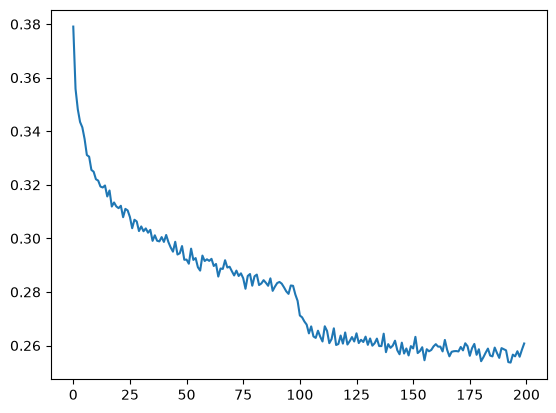

In [113]:
# this is one of the plots we will be looking to improve
# plt.plot(lossi)

# our small batch size means our loss for each batch can fluctuate wildly

# this takes the average at every 1000 steps or so  and plots that instead
short_loss = torch.tensor(lossi).view(-1, 1000).mean(1)
plt.plot(short_loss)

In [114]:
# put layers into eval mode (needed for batchnorm especially)
for layer in model.layers:
  layer.training = False

In [115]:
# evaluate the loss
@torch.no_grad() # this decorator disables gradient tracking inside pytorch
def split_loss(split):
  x,y = {
    'train': (X_train, Y_train),
    'val': (X_val, Y_val),
    'test': (X_test, Y_test),
  }[split]
  logits = model(x)
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 1.7874855995178223
val 1.9916553497314453


### Performance notes

Opening performance, block size 3, 200k interations, 10dim embeddings, 200 hidden layer: train 2.0441951751708984, val 2.10844087600708

First tweak: block size **8**, 200k iterations, 10dim embeddings, 200 hidden layer: train 1.9282915592193604, val 2.030041456222534

Quick note on above, this change adds 10k parameters to train. This is because our first layer goes from 3input x 10embeddings to 8input x 10embeddings i.e. 50 more neurons in input. This then causes 50 x 200 more required weights between then input and the hidden layer = 10k

Switching to a deeper model with the wavenet: block size 8, 200k iterations, 10dim embeddings, 68 hidden layer to bring total params back to ~ 22k: train 1.92133367061615, val 2.035421848297119

Quick note on above: initially, going from wider to deeper didnt really help, but we need to investigate our batch norm layer and tweak hyperparams

Final switch: block size 8, 200k iterations, 24dim embeddings, 128 hidden layer gives 76579 params: train 1.7874855995178223, val 1.9916553497314453

In [116]:
# sample from the model
for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      # forward pass the neural net
      logits = model(torch.tensor([context]))
      probs = F.softmax(logits, dim=1)
      # sample from the distribution
      ix = torch.multinomial(probs, num_samples=1).item()
      # shift the context window and track the samples
      context = context[1:] + [ix]
      out.append(ix)
      # if we sample the special '.' token, break
      if ix == 0:
        break
    
    print(''.join(i_to_s[i] for i in out)) # decode and print the generated word

lakelin.
arieley.
taylen.
ash.
safe.
donavik.
leonas.
hudyn.
galley.
laurnei.
tristaf.
daniah.
stephania.
njay.
arrun.
islak.
saharain.
gamonti.
radhil.
viomora.
